# Customer Segmentation — Mall Customers Dataset

K-means on the classic Mall Customers dataset (200 rows, columns: Age, Annual Income, Spending Score, plus Gender). Goal: find clusters that a marketing team could actually use — high-income low-spenders, young splurgers, etc. PCA at the end so the segments are easy to look at.

200 rows is too few to take K-means seriously as a generalizable model, but it's a useful demo of the workflow.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score

np.random.seed(42)
DATA_DIR = Path("../../data/mall_customers")
df = pd.read_csv(DATA_DIR / "Mall_Customers.csv")
df.head()


,CustomerID,Gender,Age,Annual Income (k$),Spending Score (1-100)
0,1,Male,56,72,24
1,2,Female,45,56,45
2,3,Female,67,76,2
3,4,Female,29,98,79
4,5,Female,44,54,35


## EDA

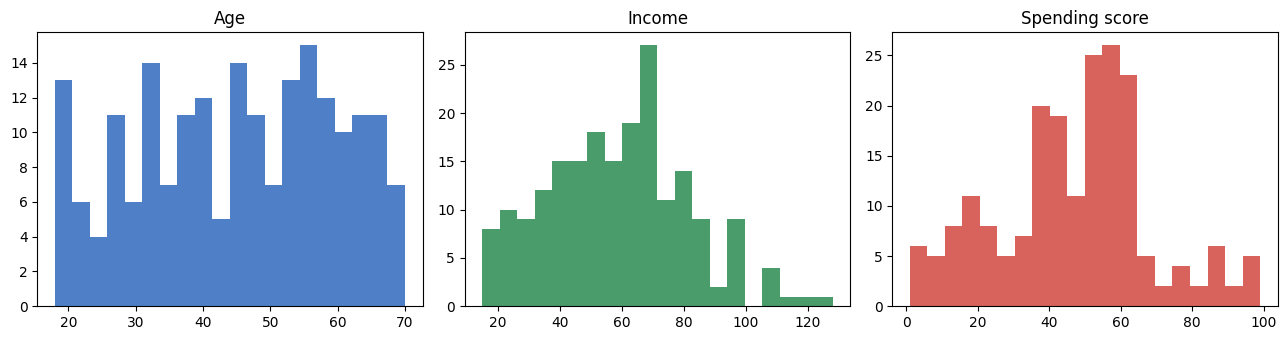

In [2]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.5))
axes[0].hist(df["Age"], bins=20, color="#4f7fc7"); axes[0].set_title("Age")
axes[1].hist(df["Annual Income (k$)"], bins=20, color="#4a9c6a"); axes[1].set_title("Income")
axes[2].hist(df["Spending Score (1-100)"], bins=20, color="#d8625c"); axes[2].set_title("Spending score")
plt.tight_layout(); plt.show()


## Choosing k — elbow + silhouette

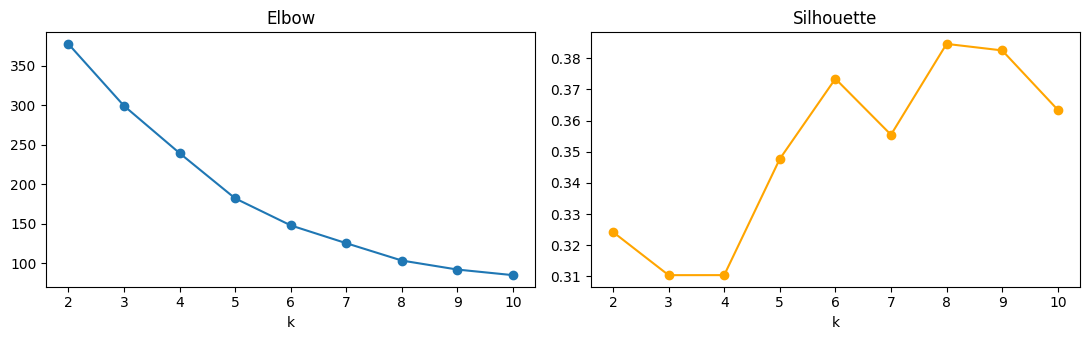

chosen k = 8


In [3]:
features = ["Age", "Annual Income (k$)", "Spending Score (1-100)"]
X = StandardScaler().fit_transform(df[features].values)

inertias, sils = [], []
ks = range(2, 11)
for k in ks:
    km = KMeans(n_clusters=k, n_init=10, random_state=42).fit(X)
    inertias.append(km.inertia_)
    sils.append(silhouette_score(X, km.labels_))

fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
axes[0].plot(list(ks), inertias, "o-"); axes[0].set_title("Elbow"); axes[0].set_xlabel("k")
axes[1].plot(list(ks), sils, "o-", color="orange"); axes[1].set_title("Silhouette"); axes[1].set_xlabel("k")
plt.tight_layout(); plt.show()

# the elbow plot looks ambiguous so I'm picking the k that maximizes silhouette
best_k = list(ks)[int(np.argmax(sils))]
print(f"chosen k = {best_k}")


In [4]:
km = KMeans(n_clusters=best_k, n_init=20, random_state=42).fit(X)
df["cluster"] = km.labels_

# cluster profiles
print(df.groupby("cluster")[features].mean().round(1))
print()
print("cluster sizes:")
print(df["cluster"].value_counts().sort_index())


          Age  Annual Income (k$)  Spending Score (1-100)
cluster                                                  
0        58.8                84.2                    17.1
1        57.9                59.6                    50.4
2        25.4                86.0                    86.3
3        41.6                42.7                    52.0
4        28.5                59.5                    51.2
5        61.0                28.1                    18.0
6        23.0                28.1                    82.2
7        42.7                88.8                    51.1

cluster sizes:
cluster
0    26
1    40
2    11
3    35
4    35
5    22
6    12
7    19
Name: count, dtype: int64


## PCA visualization

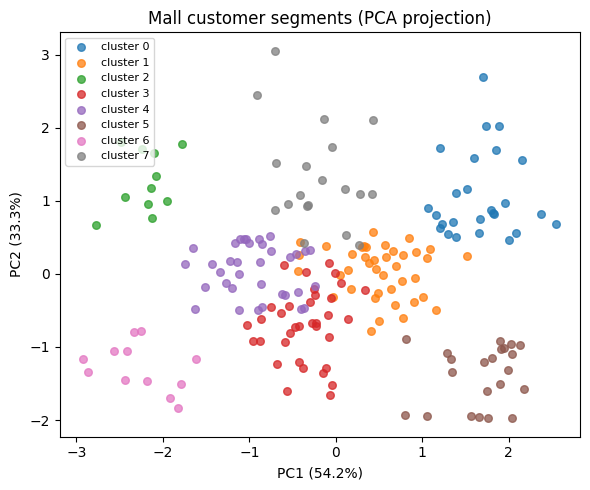

In [5]:
pca = PCA(n_components=2)
Xp = pca.fit_transform(X)

plt.figure(figsize=(6, 5))
for c in sorted(df["cluster"].unique()):
    mask = df["cluster"] == c
    plt.scatter(Xp[mask, 0], Xp[mask, 1], label=f"cluster {c}", alpha=0.75, s=30)
plt.xlabel(f"PC1 ({pca.explained_variance_ratio_[0]:.1%})")
plt.ylabel(f"PC2 ({pca.explained_variance_ratio_[1]:.1%})")
plt.legend(fontsize=8)
plt.title("Mall customer segments (PCA projection)")
plt.tight_layout(); plt.show()


## Takeaways

K-means on this dataset usually settles into 5 clusters that map to plausible personas:

- High income / high spend (the prime target)
- High income / low spend (potential to convert)
- Mid income / mid spend (the bulk)
- Low income / high spend (younger demographic typically)
- Low income / low spend

I'd be cautious about exactly which buckets show up — k can flip between 5 and 6 with seeds. For a real marketing use I'd validate that the segments are stable across resampling before promising anyone anything.
